# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Answer:** The goal is to predict whether a breast tumor is malignant or benign using 30 numeric features from cell nuclei. This is a supervised binary classification problem because the dataset has labeled examples. A false negative is more costly because predicting a malignant tumor as benign could delay treatment. Success will be measured using accuracy, precision, recall, and especially recall for malignant tumors.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# metadata
print(breast_cancer_wisconsin_diagnostic.metadata)

# variable information
print(breast_cancer_wisconsin_diagnostic.variables)


{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal': None, 'DOI': '1

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [ ]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [ ]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
...
print("Shape:", df.shape)
print("Data types:")
print(df.dtypes.value_counts())

print("\nFirst 5 rows:")
display(df.head())

Shape: (569, 31)
Data types:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [ ]:
# TODO: class counts and percentages
...
print("Class Counts:")
print(df["target"].value_counts())

print("\nClass Percentages:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

Class Counts:
target
1    357
0    212
Name: count, dtype: int64

Class Percentages:
target
1    62.74
0    37.26
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [ ]:
# TODO: describe().T, then the 10 largest skewness values
...
display(df.describe().T)

skewness = df.drop(columns=["target"]).skew()
display(skewness.reindex(skewness.abs().sort_values(ascending=False).head(10).index))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [ ]:
# TODO: correlation with target, sorted
...
correlation = df.corr(numeric_only=True)["target"].drop("target")

display(correlation.sort_values(ascending=False))

,target
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972
concavity error,-0.253730
compactness error,-0.292999
worst fractal dimension,-0.323872
mean symmetry,-0.330499
mean smoothness,-0.358560


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Answer:** The class proportions show whether the dataset is balanced, so accuracy alone may not be enough. Recall is important because missing a malignant tumor is more costly. Skewness shows if feature values are unevenly distributed, so transforms like log transformation may help improve the model.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

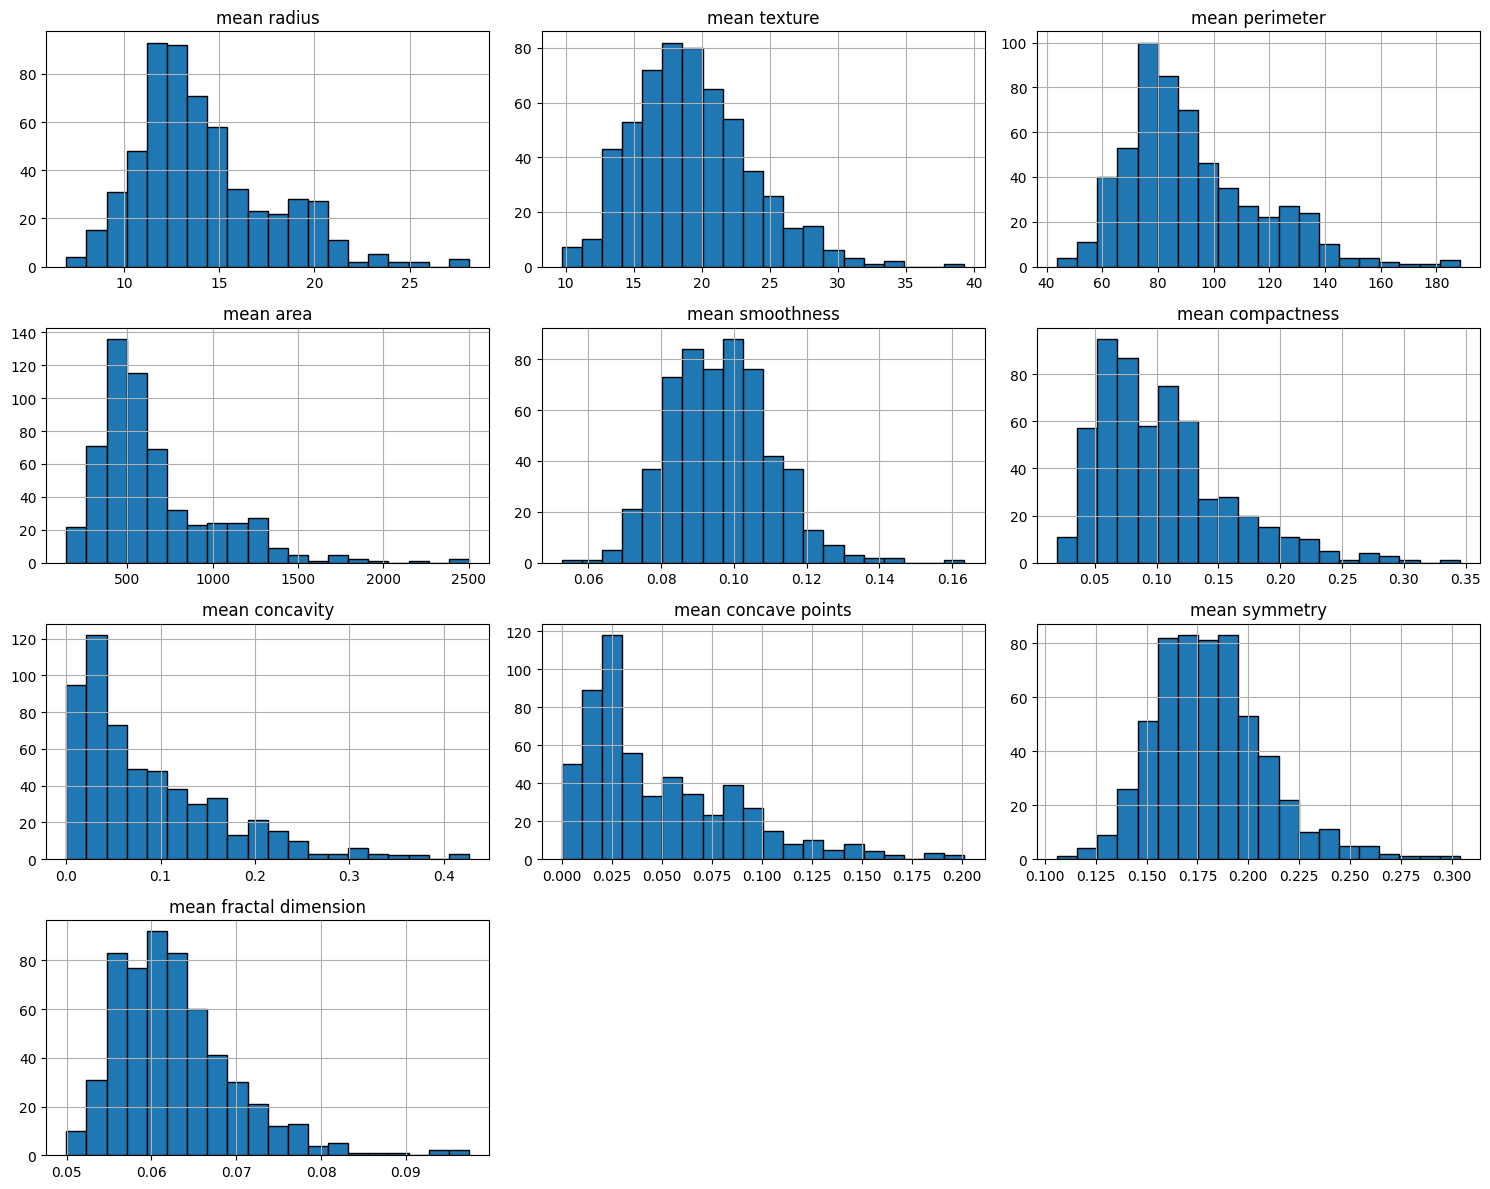

In [ ]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
...
import matplotlib.pyplot as plt

# Plot histograms of all mean features
df.filter(like="mean").hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

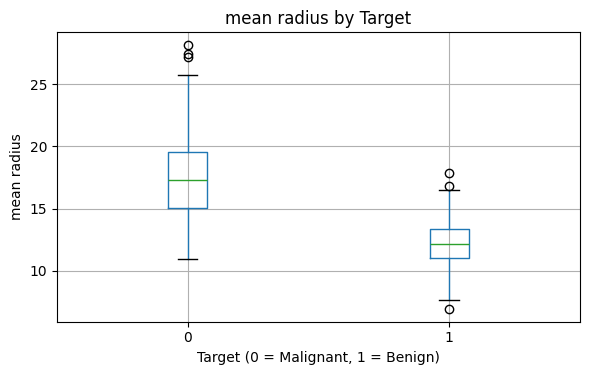

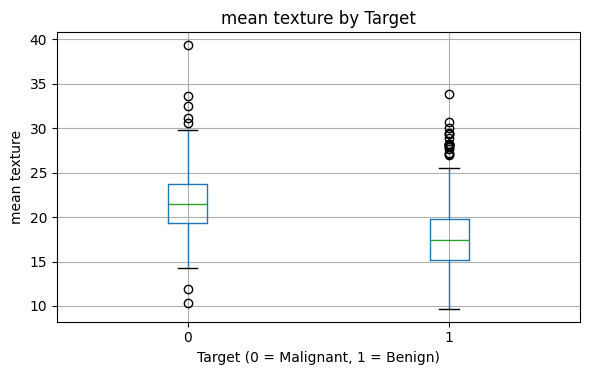

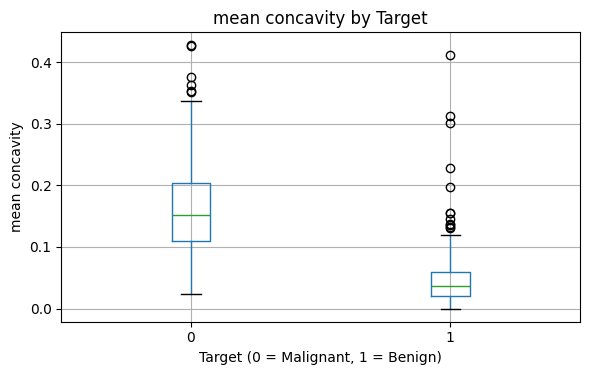

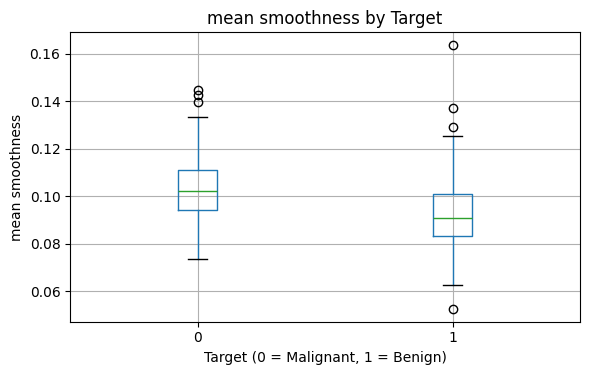

In [ ]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
...
import matplotlib.pyplot as plt

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

for feature in features:
    df.boxplot(column=feature, by="target", figsize=(6, 4))
    plt.title(f"{feature} by Target")
    plt.suptitle("")
    plt.xlabel("Target (0 = Malignant, 1 = Benign)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

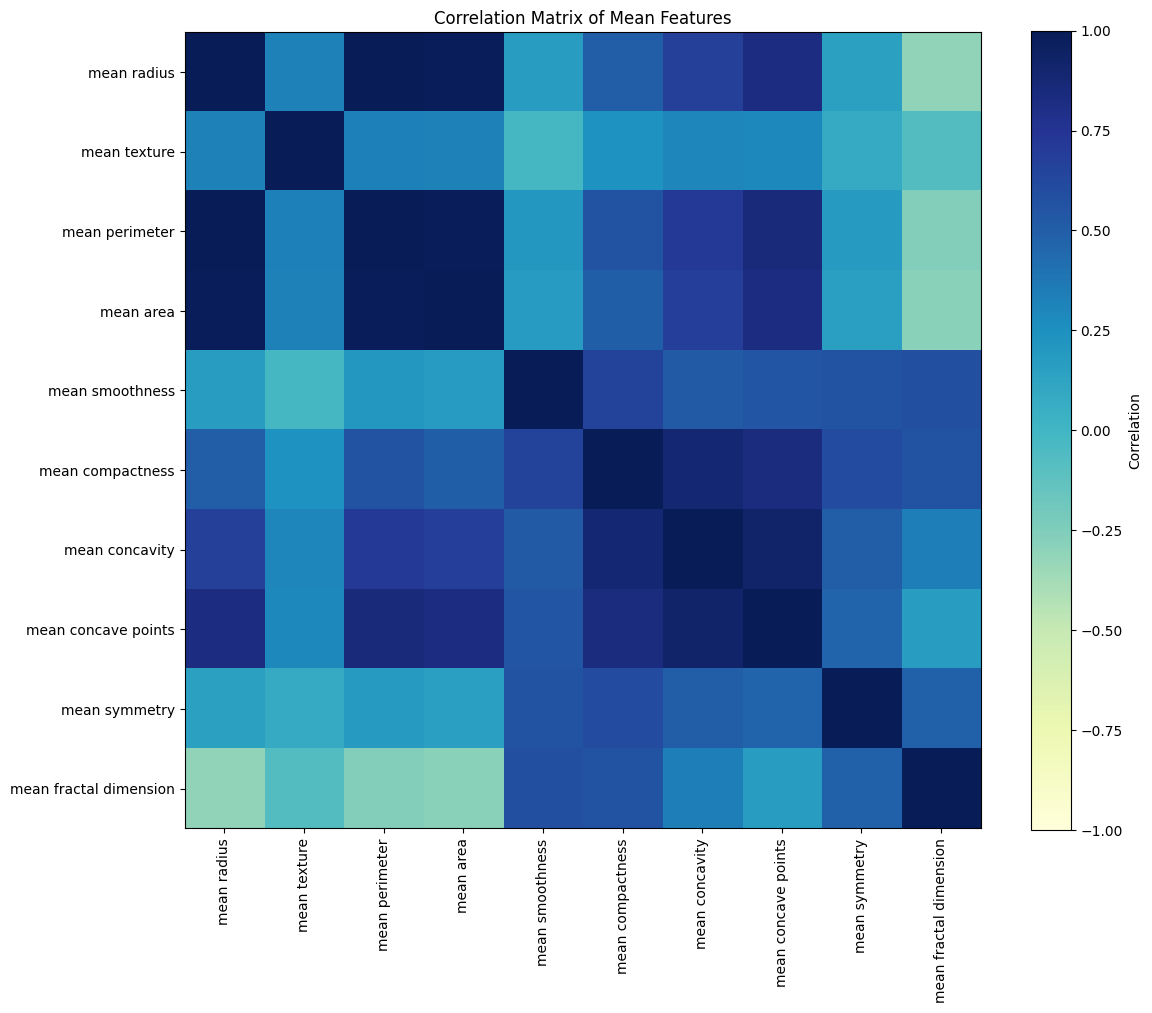

In [ ]:
# TODO: correlation matrix of the "mean" features drawn with imshow
...
import matplotlib.pyplot as plt
import numpy as np

mean_features = df.filter(like="mean")

corr_matrix = mean_features.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr_matrix, cmap="YlGnBu", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Correlation Matrix of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

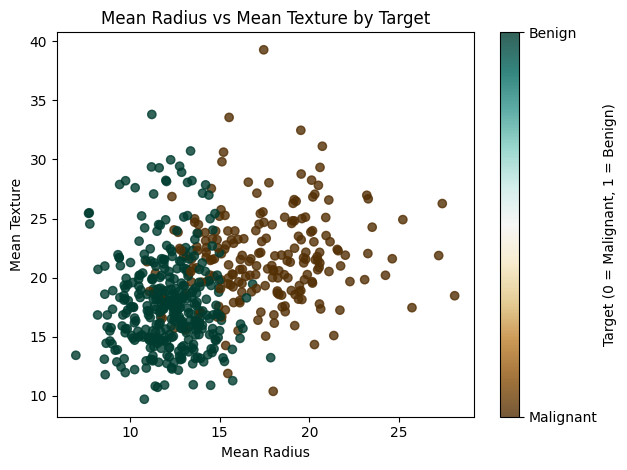

In [ ]:
# TODO: coloured scatter plot with axis labels and a colourbar
...
import matplotlib.pyplot as plt

scatter = plt.scatter(
    df["mean radius"],
    df["mean texture"],
    c=df["target"],
    cmap="BrBG",
    alpha=0.8
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Mean Radius vs Mean Texture by Target")

cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Malignant", "Benign"])

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Answer:** Features like mean radius, mean perimeter, and mean area appear redundant because they measure similar things. Features such as mean concavity, mean concave points, and worst radius may separate malignant and benign tumors more clearly.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier

In [ ]:
# TODO: total missing values and duplicated rows
...
total_missing = df.isnull().sum().sum()

total_duplicates = df.duplicated().sum()

print("Total Missing Values:", total_missing)
print("Total Duplicate Rows:", total_duplicates)

X = df.drop(columns="target")
y = df["target"]

Total Missing Values: 0
Total Duplicate Rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [ ]:
# TODO: IQR outlier count per feature
...

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((X < lower_bound) | (X > upper_bound)).sum()

top_10_outliers = outlier_counts.sort_values(ascending=False).head(10)

print("Top 10 Features with the Most Outliers:")
print(top_10_outliers)


Top 10 Features with the Most Outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Answer:** No, I would not delete the outlying rows because they may contain important information about breast cancer characteristics. Removing them could lead to losing useful data and affect the accuracy of the model. Instead, I would keep the outliers and let the model learn from them.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...
import numpy as np
corr_matrix = X.corr().abs()
upper = corr_matrix.where(
 np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column for column in upper.columns
    if any(upper[column] > 0.95)
]
print("Highly Correlated Features:")
print(high_corr_features)



Highly Correlated Features:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
...
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y.values.ravel())

scores = pd.Series(selector.scores_, index=X.columns)

scores = scores.sort_values(ascending=False)

print("Top 10 Features:")
print(scores.head(10))

Top 10 Features:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
...
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = LogisticRegression(max_iter=10000)

rfe = RFE(estimator=model, n_features_to_select=10)
rfe.fit(X_scaled, y.values.ravel())

rfe_features = X.columns[rfe.support_].tolist()

print("Selected RFE Features:")
print(rfe_features)

Selected RFE Features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

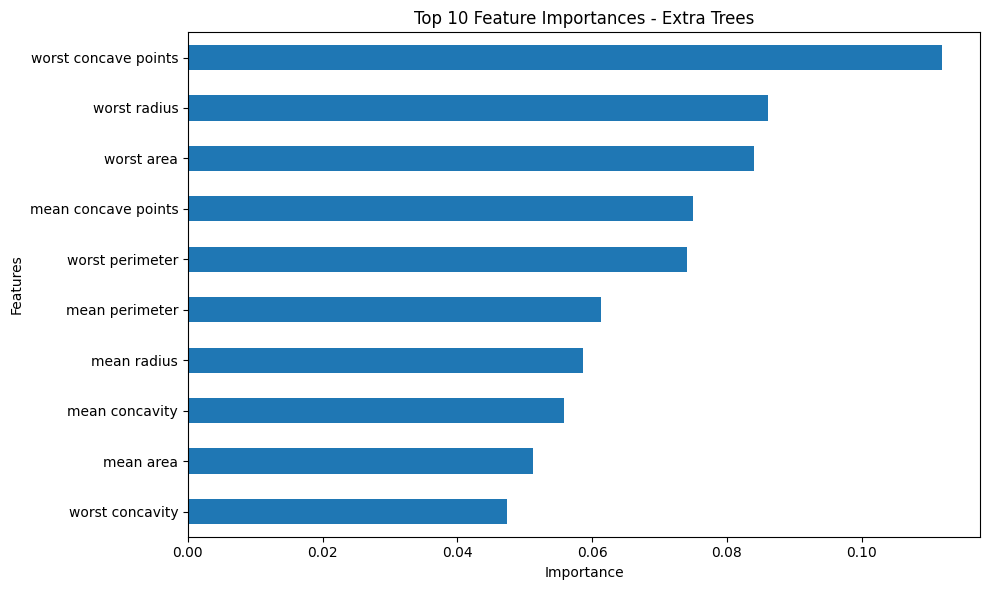

In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
...
import matplotlib.pyplot as plt

etc = ExtraTreesClassifier(n_estimators=200, random_state=7)
etc.fit(X, y.values.ravel())

imp = pd.Series(etc.feature_importances_, index=X.columns)

top_10_imp = imp.sort_values(ascending=True).tail(10)

plt.figure(figsize=(10, 6))
top_10_imp.plot(kind='barh')

plt.title("Top 10 Feature Importances - Extra Trees")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods
...
kbest_features = scores.head(10).index.tolist()

extra_trees_features = imp.nlargest(10).index.tolist()

votes = pd.Series(
    kbest_features + rfe_features + extra_trees_features
).value_counts()

selected = votes[votes >= 2].index.tolist()

print("Final Selected Features:")
print(selected)

print("\nTotal Selected Features:", len(selected))

Final Selected Features:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'worst area', 'worst concavity', 'mean perimeter', 'mean radius', 'mean area', 'mean concavity']

Total Selected Features: 10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
# TODO: train_test_split with stratify=y
...
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
# TODO: fit both scalers on X_train and print the verifying statistics
...
mm_scaler = MinMaxScaler()
X_train_mm = pd.DataFrame(
    mm_scaler.fit_transform(X_train),
    columns=X_train.columns
)

print("StandardScaler (first 4 features)")
print("Mean:")
print(X_train_std.iloc[:, :4].mean())
print("\nStandard Deviation:")
print(X_train_std.iloc[:, :4].std())

print("\nMinMaxScaler (first 4 features)")
print("Minimum:")
print(X_train_mm.iloc[:, :4].min())
print("\nMaximum:")
print(X_train_mm.iloc[:, :4].max())

StandardScaler (first 4 features)
Mean:
mean radius       9.369794e-17
mean texture     -3.747918e-16
mean perimeter   -5.797560e-16
mean area        -3.279428e-16
dtype: float64

Standard Deviation:
mean radius       1.001101
mean texture      1.001101
mean perimeter    1.001101
mean area         1.001101
dtype: float64

MinMaxScaler (first 4 features)
Minimum:
mean radius       0.0
mean texture      0.0
mean perimeter    0.0
mean area         0.0
dtype: float64

Maximum:
mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [136]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
...
pca = PCA()
pca.fit(X_train_std)

cum_var = np.cumsum(pca.explained_variance_ratio_)

n_components = np.argmax(cum_var >= 0.95) + 1

print("Number of components for 95% variance:", n_components)

Number of components for 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [ ]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
...

models = {
    "LR": LogisticRegression(max_iter=10000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [ ]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
...
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

print("Mean Accuracy Comparison:")
print(summary)

Mean Accuracy Comparison:
           raw    scaled
LR    0.953768  0.982319
LDA   0.947246  0.947246
KNN   0.922947  0.964928
CART  0.927633  0.927633
NB    0.934058  0.932029
SVM   0.898696  0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Answer:** KNN, SVM, and Logistic Regression benefit the most from scaling because they are affected by differences in feature values. Scaling puts the features on a similar range, helping these models make better predictions. Decision Trees and Naive Bayes usually do not need scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...
X_train_selected = X_train[selected]

selected_results = spot_check(
    models,
    X_train_selected,
    scale=True
)

comparison = pd.DataFrame({
    "all_features_scaled": summary["scaled"],
    "selected_features_scaled": {
        name: scores.mean()
        for name, scores in selected_results.items()
    }
})

print("Feature Selection Comparison:")
print(comparison)

Feature Selection Comparison:
      all_features_scaled  selected_features_scaled
LR               0.982319                  0.960435
LDA              0.947246                  0.942995
KNN              0.964928                  0.942802
CART             0.927633                  0.925266
NB               0.932029                  0.951691
SVM              0.975797                  0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

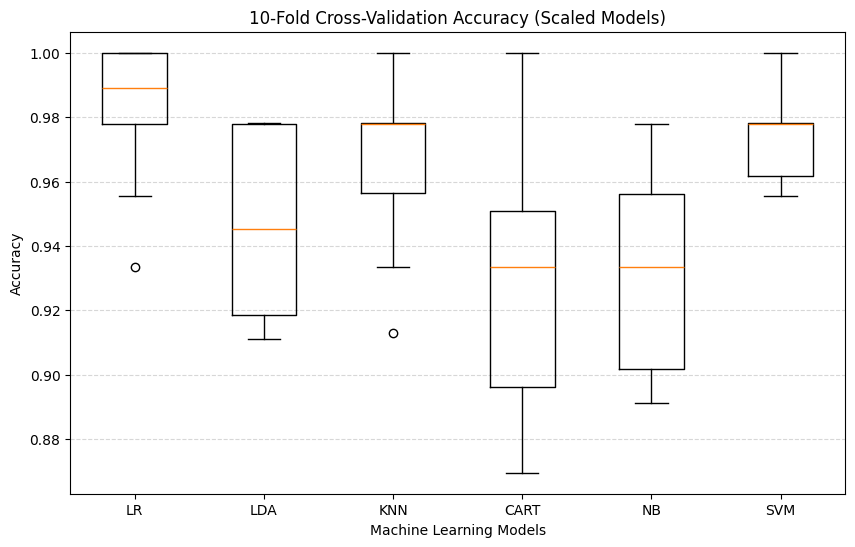

In [ ]:
# TODO: box plot of the 10 fold scores per model
...
plt.figure(figsize=(10, 6))
plt.boxplot(
    [scaled_results[name] for name in models],
    tick_labels=list(models.keys())
)
plt.title("10-Fold Cross-Validation Accuracy (Scaled Models)")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...
best_model_name = summary["scaled"].idxmax()
best_model = models[best_model_name]

print("Best Scaled Model:", best_model_name)

best_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(
        recall_score,
        pos_label=0
    )
}

cv_results = cross_validate(
    best_pipeline,
    X_train,
    y_train.values.ravel(),
    cv=kfold,
    scoring=scoring
)

print("\nEvaluation Results:")
print("Accuracy:", cv_results["test_accuracy"].mean())
print("ROC-AUC:", cv_results["test_roc_auc"].mean())
print("Malignant Recall:", cv_results["test_recall_malignant"].mean())

Best Scaled Model: LR

Evaluation Results:
Accuracy: 0.9823188405797101
ROC-AUC: 0.9921689365401333
Malignant Recall: 0.9647058823529413


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import joblib

In [ ]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train.values.ravel())

tuned_svm = svm_grid.best_estimator_

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("Best SVM Accuracy:", svm_grid.best_score_)

Best SVM Parameters:
{'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM Accuracy: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train.values.ravel())

tuned_knn = knn_grid.best_estimator_

print("Best KNN Parameters:")
print(knn_grid.best_params_)

print("Best KNN Accuracy:", knn_grid.best_score_)

Best KNN Parameters:
{'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN Accuracy: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...
ensembles = {
    "RandomForest": RandomForestClassifier(
        n_estimators=200, random_state=seed
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=seed
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=seed
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=seed
    )
}

# Evaluate ensemble models
ensemble_results = spot_check(
    ensembles,
    X_train,
    scale=False
)

# Create Random Forest for voting
rf_model = ensembles["RandomForest"]

# Create hard Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("svm", tuned_svm),
        ("knn", tuned_knn),
        ("rf", rf_model)
    ],
    voting="hard"
)

# Evaluate voting ensemble
voting_scores = cross_val_score(
    voting_model,
    X_train,
    y_train.values.ravel(),
    cv=kfold,
    scoring="accuracy"
)

print("Voting Ensemble Accuracy:", voting_scores.mean())

Voting Ensemble Accuracy: 0.9780676328502416


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series
...
all_models = {
    "Tuned SVM": tuned_svm,
    "Tuned KNN": tuned_knn,
    **ensembles,
    "Voting Ensemble": voting_model
}

leaderboard = pd.Series({
    name: cross_val_score(
        model,
        X_train,
        y_train.values.ravel(),
        cv=kfold,
        scoring="accuracy",
        n_jobs=-1
    ).mean()
    for name, model in all_models.items()
}).sort_values(ascending=False)

print("Model Leaderboard:")
print(leaderboard)

Model Leaderboard:
Tuned SVM            0.980193
Voting Ensemble      0.978068
Extra Trees          0.971401
Tuned KNN            0.969275
Gradient Boosting    0.966957
RandomForest         0.964783
AdaBoost             0.962560
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Best Model: Tuned SVM

Test Accuracy:
0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



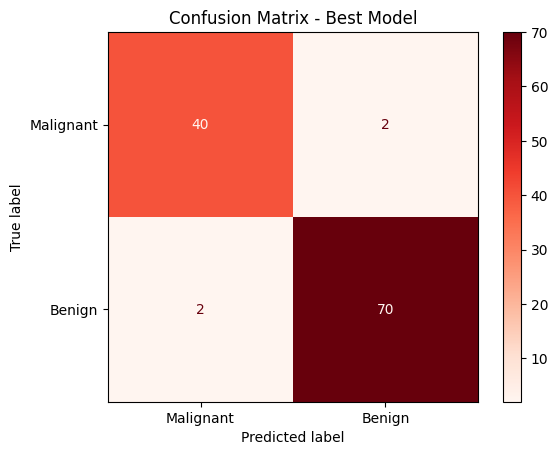

In [ ]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...
best_model_name = leaderboard.index[0]
final_model = all_models[best_model_name]

print("Best Model:", best_model_name)

final_model.fit(X_train, y_train.values.ravel())

y_pred = final_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test.values.ravel(), y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Reds")
plt.title("Confusion Matrix - Best Model")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...
joblib.dump(final_model, "best_breast_cancer_model.joblib")

loaded_model = joblib.load("best_breast_cancer_model.joblib")

reloaded_predictions = loaded_model.predict(X_test)

print("Original Predictions:")
print(y_pred[:5])

print("\nReloaded Predictions:")
print(reloaded_predictions[:5])

print("\nPredictions Match:",
      (y_pred == reloaded_predictions).all())

Original Predictions:
[0 0 1 0 1]

Reloaded Predictions:
[0 0 1 0 1]

Predictions Match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

**Answer:**
1. Leakage:
Feature selection using the whole dataset can cause data leakage because information from the test data is used during training. This can make the model's cross-validation scores look higher than they really are. To fix this, I would put feature selection inside a Pipeline so it only learns from the training data in each fold.

2. Metric Choice:
I would report recall for the malignant class because it shows how many actual cancer cases the model correctly identifies. Accuracy alone is not enough because a model can have high accuracy but still miss patients with cancer.

3. Model Choice:
If two models differ by only 0.3% in accuracy, I would choose the one with more consistent results across the folds. I would also consider which model is easier to understand and takes less time to train.

4. Generalization:
With a smaller dataset, the model may have less reliable results because there is not enough data for training. With an imbalanced dataset, accuracy may be misleading, so I would focus more on recall, precision, and F1-score.

5. Extension:
If I use another dataset, I would follow the same steps, such as cleaning the data, selecting features, splitting the data, training models, and evaluating their performance. However, I may need to change the target column, preprocessing steps, and model settings depending on the new dataset.